In [4]:
pip install opencv-python

  Using cached opencv_python-5.1.0.95-cp37-abi3-macosx_15_0_arm64.whl.metadata (20 kB)
Using cached opencv_python-5.1.0.95-cp37-abi3-macosx_15_0_arm64.whl (25.8 MB)
Note: you may need to restart the kernel to use updated packages.


# Preprocessing

In [6]:
import numpy as np 
import matplotlib.pyplot as plt 
import cv2 

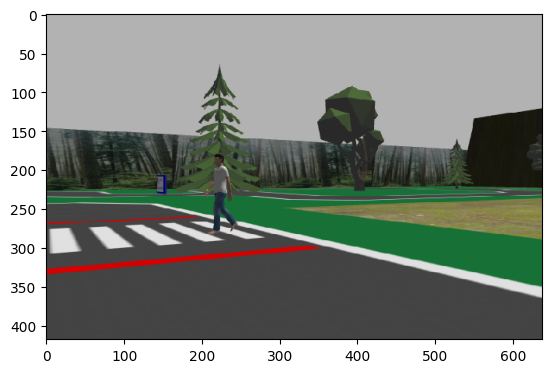

In [46]:
img_path = "/Users/annabel/Downloads/ENPH353_competition/ENPH353_Competition/src/my_controller/my_controller/testPhotos/img3.png"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb) #sanity check 

In [47]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) #convert to HSV for better colour processing 

#since red wraps around the HSV scale, we need to define lower and upper bounds for red (two ranges):
# Lower red range (0 to 10)
lower_red1 = np.array([0, 120, 70])
upper_red1 = np.array([10, 255, 255])

# Upper red range (170 to 179)
lower_red2 = np.array([170, 120, 70])
upper_red2 = np.array([179, 255, 255])

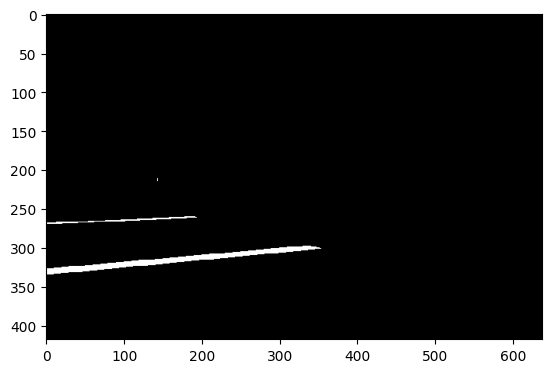

In [48]:
# 4. Create masks for both ranges and combine them
mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
red_mask = cv2.bitwise_or(mask1, mask2)

#if you wanted to extract the red parts only: 
#result = cv2.bitwise_and(img, img, mask=red_mask)

plt.imshow(red_mask, cmap="gray")

In [50]:
#close any tiny gaps before finding contours 
# I did test this on the "perfect view" and turning cases and found it unnecessary (same result for area of contour)
#maxGapSize = 20

contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print(cv2.contourArea(contours[0]))
print(len(contours))

#closed = cv2.morphologyEx(red_mask, cv2.MORPH_CLOSE, np.ones((1, maxGapSize), np.uint8))
#contours, _ = cv2.findContours(red_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
#print(cv2.contourArea(contours[0]))
#print(len(contours))

2064.5
3


In [ ]:
#find the line of best fit for contours only if their area exceeds threshold area 

thresholdArea = 500

### extra stuff

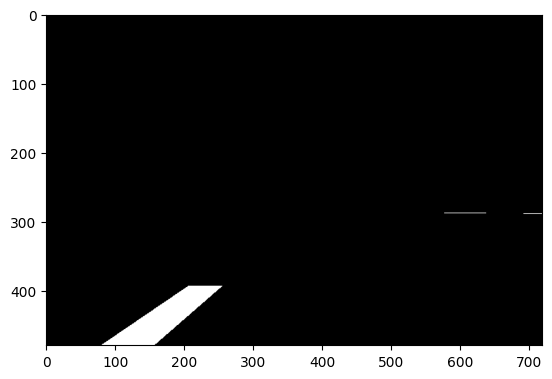

In [ ]:
gapCloseSize=25 
minLineWidth=50

closed = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, np.ones((1, gapCloseSize), np.uint8))
horiz = cv2.morphologyEx(closed, cv2.MORPH_OPEN, np.ones((1, minLineWidth), np.uint8))
plt.imshow(horiz, cmap="gray")